# Land cover statistics: Eaton and Palisades fires (sample)

*Draft for week 9, class 1. It follows L16: land cover statistics step by step, swapping the GAP/LANDFIRE 2011 data and the Thomas Fire for the Impact Observatory annual land cover maps and the Eaton and Palisades fires.*

Before we start working with the data, let's learn a Python shortcut we'll use later in this lesson.

*Instructions: For the student notebook, we will only have the title for this section.*

## List comprehensions

A **list comprehension** is a short way of writing a `for` loop that builds a new list.

### Example: doubling numbers {.unlisted}

Here is a `for` loop that doubles each number in a list:

In [1]:
# Instructions: NOT IN STUDENT NOTEBOOK
numbers = [1, 2, 3, 4]

doubled = []
for n in numbers:
    doubled.append(n * 2)

doubled

[2, 4, 6, 8]

And here is the same thing as a list comprehension:

In [2]:
doubled = [n * 2 for n in numbers]
doubled

[2, 4, 6, 8]

Read it from the inside out: "`n * 2` **for** each `n` **in** `numbers`". The square brackets tell Python to collect the results in a new list. Notice everything from the loop is still there (the loop variable `n`, the list `numbers`, and what we do with each element), just in one line.

### Example: one value from each dictionary {.unlisted}

*DO: Make a very short recap of what a dictionary is and how to access its values*

This is closer to what we will need later in the lesson. We have a list of dictionaries and want one value from each:

In [3]:
pets = [{'name': 'Tuna', 'age': 5},
        {'name': 'Bowie', 'age': 7},
        {'name': 'Momo', 'age': 17}]

pet_names = [pet['name'] for pet in pets]
pet_names

['Tuna', 'Bowie', 'Momo']

### Check-in {.unlisted}

1. Print Momo's age.
2. Use a list comprehension to make a list with the ages of the pets.

In [4]:
# Solution
# Instructions: THIS WILL NOT BE INCLUDED IN THE NOTES, JUST COMMENTED OUT
pet_ages = [pet['age'] for pet in pets]
print(pet_ages)

[5, 7, 17]


*INSTRUCTIONS: the student notebook will have a shortened version of this. Point to the website for all instructions on how to access the data and references about it.*

## About the data

In this lesson we will use three datasets.

The first one is the [10 m Annual Land Use Land Cover (9-class) V2 maps](https://planetarycomputer.microsoft.com/dataset/io-lulc-annual-v02) produced by Impact Observatory, Microsoft and Esri from Sentinel-2 imagery. This is a categorical raster with a 10 m x 10 m pixel resolution and one map per year from 2017 to 2023. We will access this data through the [Microsoft Planetary Computer (MPC) data catalog](https://planetarycomputer.microsoft.com/dataset/io-lulc-annual-v02).

The second dataset is the perimeters of the Eaton and Palisades fires, which burned in Los Angeles County in January 2025. <!-- TODO: add source and citation -->

The third dataset is a shapefile with the California state boundary, which we will only use to see where the land cover raster sits relative to the fire perimeters.

:::{.callout-tip appearance="minimal"}
Download the following folders from the [course's Google Drive]({{< var shared-data-folder >}}) and add them to a `data` directory next to your notebook:

- `Eaton_Perimeter_20250121`,
- `Palisades_Perimeter_20250121`, and
- `ca_state_boundary`.

The land cover raster is accessed through the MPC catalog, so there's nothing to download for it.
:::

## Fire perimeter preparation

Let's start by importing the necessary libraries:

In [5]:
# Instructions: WE WILL HAVE THIS CELL IN THE STUDENT NOTEBOOK
# NOTES FOR INSTRUCTOR: I will ask sudents to tell each other what these libraries are for

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd
import rioxarray as rioxr
from shapely import box

import pystac_client
import planetary_computer

from IPython.display import Image

# THIS WILL APPEAR IN THE NOTES, BUT NOT ON THE STUDENT NOTEBOOK
import matplotlib.patches as mpatches


Then import the Eaton Fire perimeter:

EPSG:3857
(20, 5)


<Axes: >

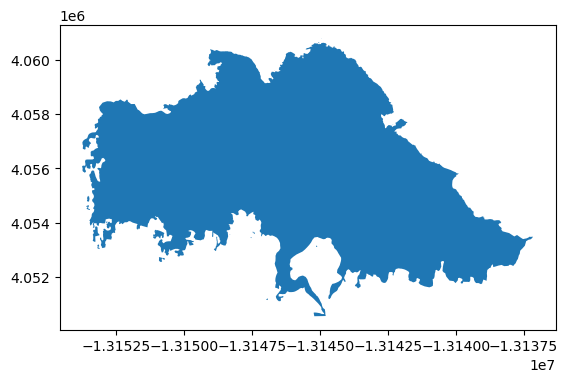

In [6]:
# Instructions: WE WILL HAVE THIS CELL IN THE STUDENT NOTEBOOK WITH INSTRUCTIONS ABOUT UPDATING THE FILE PATH
# Instructions: all the data imports taht require acces to local data should go at the top of the student notebook, 
# and thus at the top of the instructor notebook as well. 

eaton = gpd.read_file(os.path.join('data',
                                   'Eaton_Perimeter_20250121',
                                   'Eaton_Perimeter_20250121.shp')
                                   )

# THIS WILL BE DONE IN CLASS
# Examine fire perimeter data
print(eaton.crs)
print(eaton.shape)
eaton.plot()

Notice the perimeter is not a single polygon: it is made of several "Heat Perimeter" polygons. That's fine for what we'll do, since we'll use all of them together.

*Instructions: a simplified version of this will be in the student notebook.*

## Catalog search

Our goal is to retrieve the land cover data over the fire perimeter. In the [last lesson](/book/chapters/lesson-16-STAC.qmd) we used a GeoJSON-type dictionary to do the catalog search. Here we will use a list `[xmin, ymin, xmax, ymax]` with the coordinate values defining the edges of the region we want to search data over. Just as with the GeoJSON, these coordinates have to be in the EPSG:4326 CRS.

Our bounding box will come from the Eaton Fire perimeter. Notice we use method chaining to reproject and extract the bounds.

In [7]:
# Instructions: this will be blank in the student notebook.
# Create list of bounding box coords for search in 4326 CRS
eaton_bbox = list(eaton.to_crs('epsg:4326')
                       .total_bounds
                       )
eaton_bbox

[-118.16206999988188,
 34.16189200012067,
 -118.01305200016513,
 34.23783206465605]

Next, we connect to the Microsoft Planetary Computer data catalog and perform the search. The collection ID for this land cover data is `io-lulc-annual-v02`.

This collection has one map per year, so we also need to choose a year. The fires happened in January 2025 and the most recent map is for 2023, so we'll search for 2023:

In [8]:
# Instructions: WE WILL HAVE THIS CELL IN THE STUDENT NOTEBOOK

# Open MPC data catalog
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Notes to instructor: I will ask students to retrieve the items themselves during class, so they should write all the next lines
# Search MPC catalog
search = catalog.search(collections=['io-lulc-annual-v02'],
                        bbox=eaton_bbox,
                        datetime='2023')

# Retrieve search items
items = search.item_collection()
print(f"Returned {len(items)} Items")
items

Returned 2 Items


We asked for 2023 but got two items. Let's look at the time range each one covers:

In [9]:
for item in items:
    print(item.id, item.properties['start_datetime'], item.properties['end_datetime'])

11S-2023 2023-01-01T00:00:00.000000Z 2024-01-01T00:00:00.000000Z
11S-2022 2022-01-01T00:00:00.000000Z 2023-01-01T00:00:00.000000Z


Each map covers a full year, from January 1 to January 1 of the next year. The 2022 map ends on January 1, 2023, so it also matches our search for 2023.

Let's select the 2023 map and view its pre-rendered image:

In [10]:
# Note to instructor: I will pass this code via Slack and have people predict the outputs. 
# Select the 2023 map (the first item) and check it is the right one
item = items[0]
assert item.properties['start_datetime'].startswith('2023')
print(item.id)

# Display pre-rendered image
Image(url=item.assets['rendered_preview'].href, width=600)

11S-2023


We can see this is a big raster!

At this point, we can also get the class labels. This time they are stored in the item's metadata:

In [11]:
# Class codes and names from the item's metadata
class_values = item.assets['data'].extra_fields['file:values']
class_values

[{'values': [0], 'summary': 'No Data'},
 {'values': [1], 'summary': 'Water'},
 {'values': [2], 'summary': 'Trees'},
 {'values': [4], 'summary': 'Flooded vegetation'},
 {'values': [5], 'summary': 'Crops'},
 {'values': [7], 'summary': 'Built area'},
 {'values': [8], 'summary': 'Bare ground'},
 {'values': [9], 'summary': 'Snow/ice'},
 {'values': [10], 'summary': 'Clouds'},
 {'values': [11], 'summary': 'Rangeland'}]

*DO: add a check-in: what kind of object is this?*

`class_values` is a list of dictionaries, one per class, like `{'values': [0], 'summary': 'No Data'}`. We want two lists out of it: all the codes and all the names. This is a job for a list comprehension! The code is the first (and only) element of the list under `'values'`, and the name is under `'summary'`:

In [12]:
#Instructions: this cell goes only on the instructor notebook, it has instructions about how to explain it step by step

In [13]:
labels = pd.DataFrame({'code': [c['values'][0] for c in class_values],
                       'class_label': [c['summary'] for c in class_values]})
labels

,code,class_label
0,0,No Data
1,1,Water
2,2,Trees
3,4,Flooded vegetation
4,5,Crops
5,7,Built area
6,8,Bare ground
7,9,Snow/ice
8,10,Clouds
9,11,Rangeland


Notice the metadata says 0 is used for "No Data". This will be relevant in a moment.

## Explore raster

Next, we can go ahead and open the raster:

In [14]:
# Access raster data from item
lulc = rioxr.open_rasterio(item.assets['data'].href)
lulc

<xarray.DataArray (band: 1, y: 89162, x: 56684)> Size: 5GB
[5054058808 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 453kB 2.166e+05 2.166e+05 ... 7.834e+05 7.834e+05
  * y            (y) float64 713kB 4.432e+06 4.432e+06 ... 3.54e+06 3.54e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     0
    scale_factor:   1.0
    add_offset:     0.0

Notice that `band` is a dimension of length 1. We can go ahead and "squeeze" the raster to simplify it. We'll also check the raster's data type and CRS:

In [15]:
# Remove length 1 dimension (band)
lulc = lulc.squeeze().drop_vars('band')
print("Sizes of dimensions:", dict(lulc.sizes))
print("Data type:", lulc.dtype)
print("CRS:", lulc.rio.crs)

Sizes of dimensions: {'y': 89162, 'x': 56684}
Data type: uint8
CRS: EPSG:32611


Next, let's look at how the raster is located with respect to the Eaton Fire perimeter and the CA state boundary:

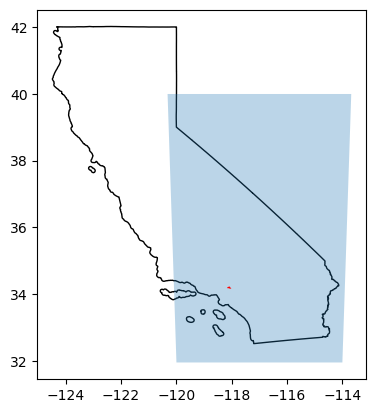

In [16]:
# Create GeoDataFrame from raster bounding box
lulc_bbox = gpd.GeoDataFrame(geometry = [box(*lulc.rio.bounds())],
                             crs = lulc.rio.crs)

# IN THE STUDENT NOTEBOOK THIS DATA IMPORT SHOULD BE AT THE TOP.
ca = gpd.read_file(os.path.join('data',
                                'ca_state_boundary',
                                'ca_state_boundary.shp'))

# ------------------------------------------------------------------
# NOTE FOR INSTRUCTOR: I will passs this code via slack and we will copy it so that students can read it.
# Maybe I could insert a bug so that people could fix it? Maybe the to_crs missing. 

# Plot raster boundary, fire perimeter, and CA boundary
fig, ax = plt.subplots()
ca.plot(ax=ax, color='white', edgecolor ='black')

# Reproject lulc_bbox and fire perimeter to match CA crs
lulc_bbox.to_crs(ca.crs).plot(ax=ax, alpha=0.3)
eaton.to_crs(ca.crs).plot(ax=ax, color='red')

plt.show()

We can see the raster covers a big area relative to the fire perimeter. Since we want to calculate the land cover statistics within the fire perimeter, we will have to clip the raster to this area.

## Clip raster to geometry

Before clipping, let's check the raster's no-data value, since `rio.clip()` will use it to fill the pixels outside the fire perimeter:

In [17]:
print('No-data value: ', lulc.rio.nodata)

No-data value:  0


This matches the item's metadata: 0 means "No Data". Since the raster already has a no-data value, we don't need to set one ourselves.


In our [first lesson about rasters](/book/chapters/lesson-15-rioxarray/lesson-15-rioxarray.qmd) we saw how to clip a raster to a rectangular region. In our case, we want to clip the raster exactly to the fire perimeter. Clipping can be a costly operation for such a big raster relative to a detailed geometry. So we will perform the clipping in two steps:

1. Clip the raster to the fire perimeter bounding box using [`rio.clip_box()`](https://vylor.github.io/rioxarray/stable/rioxarray.html#rioxarray.raster_array.RasterArray.clip_box) and then
2. Clip the simplified raster to the fire perimeter using [`rio.clip()`](https://vylor.github.io/rioxarray/stable/rioxarray.html#rioxarray.raster_array.RasterArray.clip).

Why bother? To clip to a polygon, `rio.clip()` builds a mask with one true/false value per pixel of the raster it receives. Our raster has almost 90,000 x 57,000 pixels, about 5 billion values! Clipping to the bounding box first is fast, because it only selects rows and columns, and it shrinks the raster to about a million pixels before `rio.clip()` builds its mask.

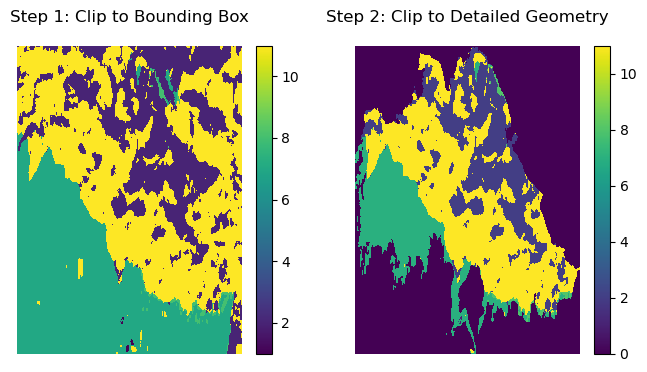

In [18]:
# Match CRSs and verify update
eaton_match = eaton.to_crs(lulc.rio.crs)
assert eaton_match.crs == lulc.rio.crs

# Clip large raster to detailed geometry in two steps
lulc_step1 = lulc.rio.clip_box(*eaton_match.total_bounds)
lulc_step2 = lulc_step1.rio.clip(eaton_match.geometry)

# ------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

# Plot the first clipped raster
lulc_step1.plot(ax=ax[0])
ax[0].set_title("Step 1: Clip to Bounding Box")
ax[0].axis("off")

# Plot the second clipped raster
lulc_step2.plot(ax=ax[1])
ax[1].set_title("Step 2: Clip to Detailed Geometry")
ax[1].axis("off")

plt.show()

We can also do both steps at once using method chaining:

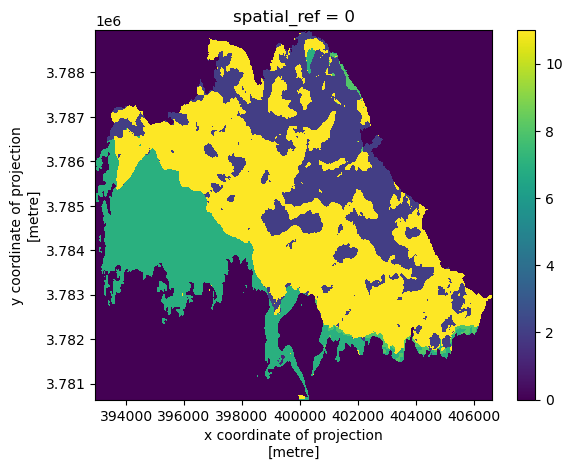

In [19]:
lulc_clip = (lulc.rio.clip_box(*eaton_match.total_bounds)
                 .rio.clip(eaton_match.geometry)
                 )

# Examine results
lulc_clip.plot()

## Categorical or continuous?

### Check-in {.unlisted}

Look at the colorbar in the plot above. Is land cover *categorical* data (each number is a label for a category) or *continuous* data (each number is a measurement)? What would a pixel with a value of 6 mean?

In a categorical raster the numbers are just codes: there is no order and nothing in between two classes. A continuous colormap like the default one suggests both, so a better choice is a **categorical colormap**, with one distinct color per class.

The MPC uses an official color for each class of this land cover product, listed in its [class map for `io-lulc-9-class`](https://planetarycomputer.microsoft.com/api/data/v1/legend/classmap/io-lulc-9-class) as RGBA values (red, green, blue, transparency). Let's add them to our `labels` data frame as hex codes, in the same order as the codes. No Data is fully transparent in the official map, so we'll use white for it:

In [20]:
# Official colors from the MPC class map, as hex codes
labels['color'] = ['white',    # No Data
                   '#419bdf',  # Water
                   '#397d49',  # Trees
                   '#7a87c6',  # Flooded vegetation
                   '#e49635',  # Crops
                   '#c4281b',  # Built area
                   '#a59b8f',  # Bare ground
                   '#a8ebff',  # Snow/ice
                   '#616161',  # Clouds
                   '#e3e2c3']  # Rangeland
labels

,code,class_label,color
0,0,No Data,white
1,1,Water,#419bdf
2,2,Trees,#397d49
3,4,Flooded vegetation,#7a87c6
4,5,Crops,#e49635
5,7,Built area,#c4281b
6,8,Bare ground,#a59b8f
7,9,Snow/ice,#a8ebff
8,10,Clouds,#616161
9,11,Rangeland,#e3e2c3


To use these colors, we give `.plot()` two lists:

- `levels`: the edges between classes. Each class goes from its own code up to the next one (Trees from 2 to 4, Flooded vegetation from 4 to 5, ...), and we add 12 as the last edge.
- `colors`: one color per class.

Since the colors are now categories, a legend works better than a colorbar. We'll make one entry per class present in the clipped raster:

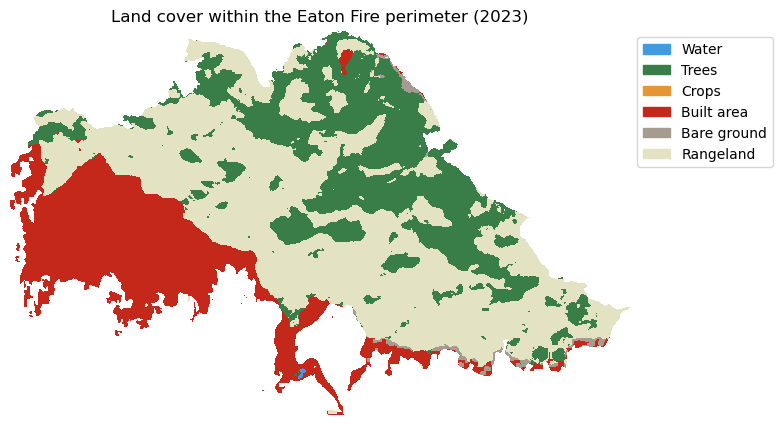

In [21]:
# NOTE FOR INSTRUCTOR: I need to import this at the top to run this cell during class
#import matplotlib.patches as mpatches

# Classes present in the clipped raster (without No Data)
present = labels[labels['code'].isin(np.unique(lulc_clip)) & (labels['code'] != 0)]

# One legend entry per class
# zip() pairs up the colors and names: ('#419bdf', 'Water'), ('#397d49', 'Trees'), ...
legend_entries = [mpatches.Patch(color=color, label=name)
                  for color, name in zip(present['color'], present['class_label'])]

fig, ax = plt.subplots(figsize=(8, 5))
lulc_clip.plot(ax=ax,
               levels=list(labels['code']) + [12],
               colors=list(labels['color']),
               add_colorbar=False)
ax.legend(handles=legend_entries, loc='upper left', bbox_to_anchor=(1, 1))
ax.set_title('Land cover within the Eaton Fire perimeter (2023)')
ax.axis('off')
plt.show()

## Land cover statistics

In the rest of this lesson we will calculate land cover statistics within the Eaton Fire perimeter. The following exercises will guide you through this process.

*Solutions are included below each exercise in this sample.*

1. Use the `numpy` function `np.unique()` to get the number of pixels per class in `lulc_clip`.

2. Create a data frame `pix_counts` with two columns: column one must be the code numbers for the pixels in `lulc_clip` and column two must be the number of pixels corresponding to each code. HINT: [check our class notes on `pandas.DataFrame`s](/book/chapters/lesson-2-series-dataframes.qmd)

In [22]:
unique_counts = np.unique(lulc_clip, return_counts=True)

pix_counts = pd.DataFrame({'code':unique_counts[0],
                           'n_pixels':unique_counts[1]})

pix_counts = pix_counts[pix_counts['code']!=0]  # Remove no-data pixels
pix_counts

,code,n_pixels
1,1,210
2,2,155858
3,5,4
4,7,130282
5,8,5328
6,11,276882


3. Use the `labels` data frame to add the class names to the codes in the `pix_counts` data frame. Store the resulting data frame as `classes`.

In [23]:
classes = pd.merge(left=labels,
                   right=pix_counts,
                   on='code')
classes

,code,class_label,color,n_pixels
0,1,Water,#419bdf,210
1,2,Trees,#397d49,155858
2,5,Crops,#e49635,4
3,7,Built area,#c4281b,130282
4,8,Bare ground,#a59b8f,5328
5,11,Rangeland,#e3e2c3,276882


4. What *area* within the fire perimeter (in km²) was classified as built area? HINT: what is the raster's resolution?

In [24]:
area_per_pixel = 10**2  # In meters^2
built = classes[classes['class_label']=='Built area']
built['n_pixels'].sum() * area_per_pixel / 1000**2

13.0282

5. Store the total number of pixels within the fire perimeter as a variable `total_pixels`.

6. Add the percentage of area covered by each class as a new column `percentage` to the `classes` data frame. Sort the data frame by percentage coverage in descending order.

In [25]:
total_pixels = classes['n_pixels'].sum()

classes['percentage'] = classes['n_pixels']/total_pixels * 100
classes = classes.sort_values(by='percentage', ascending=False)
classes

,code,class_label,color,n_pixels,percentage
5,11,Rangeland,#e3e2c3,276882,48.698475
1,2,Trees,#397d49,155858,27.412569
3,7,Built area,#c4281b,130282,22.914219
4,8,Bare ground,#a59b8f,5328,0.937098
0,1,Water,#419bdf,210,0.036935
2,5,Crops,#e49635,4,0.000704


7. Create a horizontal bar plot showing the classes with more than 1% land cover, with the largest class at the top. For example:

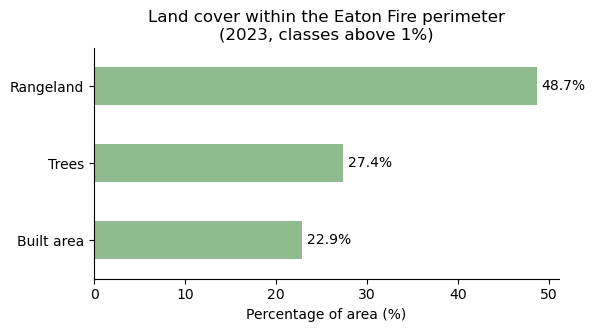

In [26]:
# Keep classes above 1% and sort so the largest class ends up at the top
plot_data = (classes[classes['percentage'] > 1]
                    .set_index('class_label')
                    .sort_values(by='percentage')
                    )

fig, ax = plt.subplots(figsize=(6, 3))

plot_data['percentage'].plot(kind='barh',
                             ax=ax,
                             color='darkseagreen')

# Add the percentage at the end of each bar
for i, value in enumerate(plot_data['percentage']):
    ax.text(value + 0.5, i, f"{value:.1f}%", va='center')

ax.set_title('Land cover within the Eaton Fire perimeter\n(2023, classes above 1%)')
ax.set_xlabel('Percentage of area (%)')
ax.set_ylabel('')

# Remove top and right edges of the plot
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

8. Check: the total area of the land cover pixels should be close to the area of the fire perimeter. Calculate both in km² and compare them.

In [27]:
pixel_area = total_pixels * area_per_pixel / 1000**2
perimeter_area = eaton_match.area.sum() / 1000**2
print(f"From pixels: {pixel_area:.1f} km²")
print(f"From perimeter: {perimeter_area:.1f} km²")

From pixels: 56.9 km²
From perimeter: 56.9 km²


9. Repeat the analysis for the Palisades Fire and compare the land cover within the two fire perimeters. Does the same raster cover both fires?

In [28]:
palisades = gpd.read_file(os.path.join('data',
                                       'Palisades_Perimeter_20250121',
                                       'Palisades_Perimeter_20250121.shp')
                                       )
palisades_match = palisades.to_crs(lulc.rio.crs)

lulc_clip_pal = (lulc.rio.clip_box(*palisades_match.total_bounds)
                     .rio.clip(palisades_match.geometry)
                     )

unique_counts = np.unique(lulc_clip_pal, return_counts=True)
pix_counts_pal = pd.DataFrame({'code':unique_counts[0],
                               'n_pixels':unique_counts[1]})
pix_counts_pal = pix_counts_pal[pix_counts_pal['code']!=0]

classes_pal = pd.merge(left=labels, right=pix_counts_pal, on='code')
classes_pal['percentage'] = classes_pal['n_pixels']/classes_pal['n_pixels'].sum() * 100
classes_pal.sort_values(by='percentage', ascending=False)

,code,class_label,color,n_pixels,percentage
5,11,Rangeland,#e3e2c3,480173,49.349895
1,2,Trees,#397d49,288270,29.627018
3,7,Built area,#c4281b,203132,20.876940
0,1,Water,#419bdf,1215,0.124872
4,8,Bare ground,#a59b8f,112,0.011511
2,5,Crops,#e49635,95,0.009764
